In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Superstore dataset using the correct filename
df = pd.read_csv('/content/superstore_sales.csv',
                 encoding='latin-1')

# Display first five records
print("First 5 Records:")
display(df.head())

# Display dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe())

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164



Dataset Shape:
(10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Summary Statistics:


,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


Missing values before cleaning:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Cleaned dataset shape: (9994, 22)


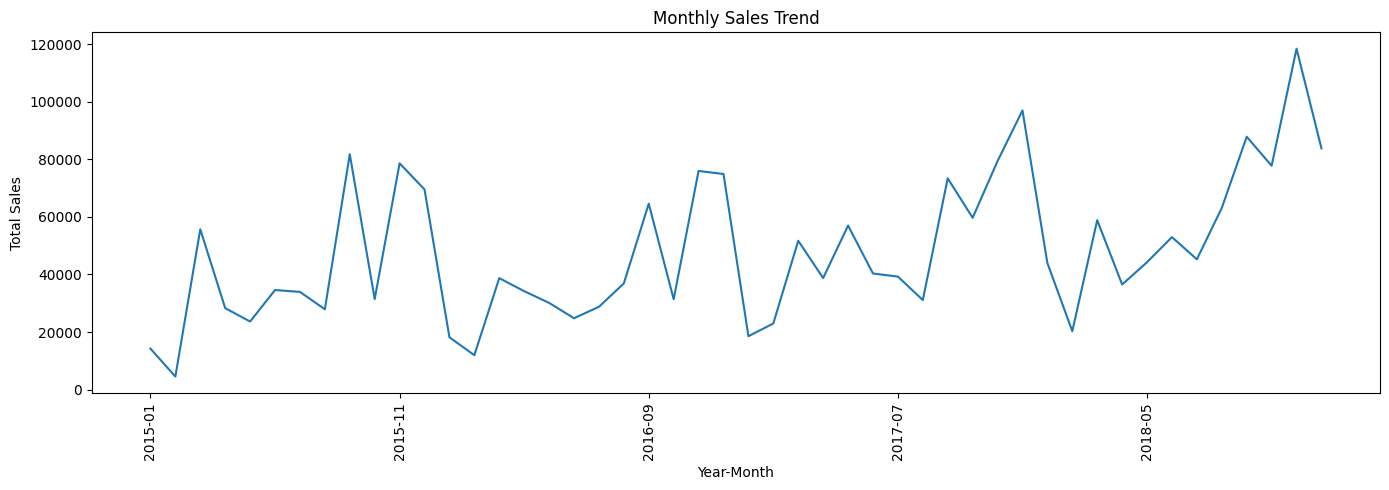

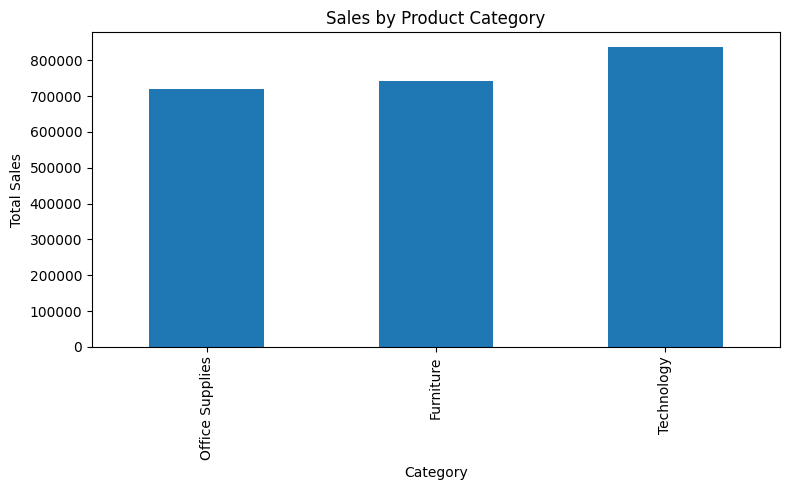

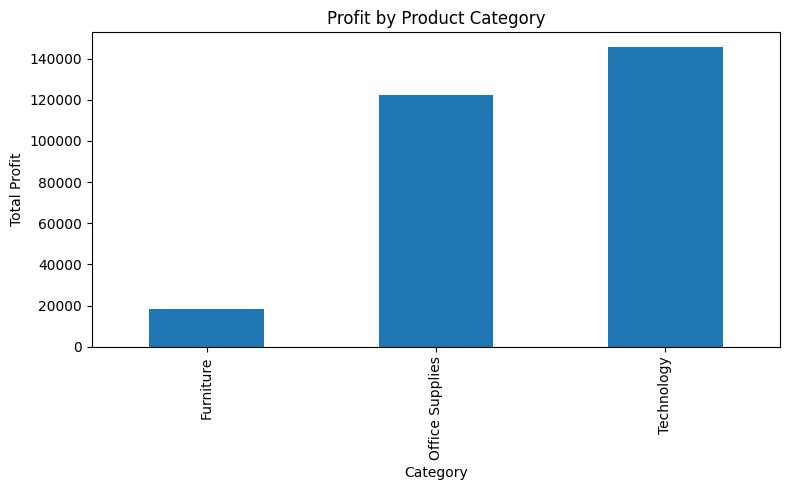

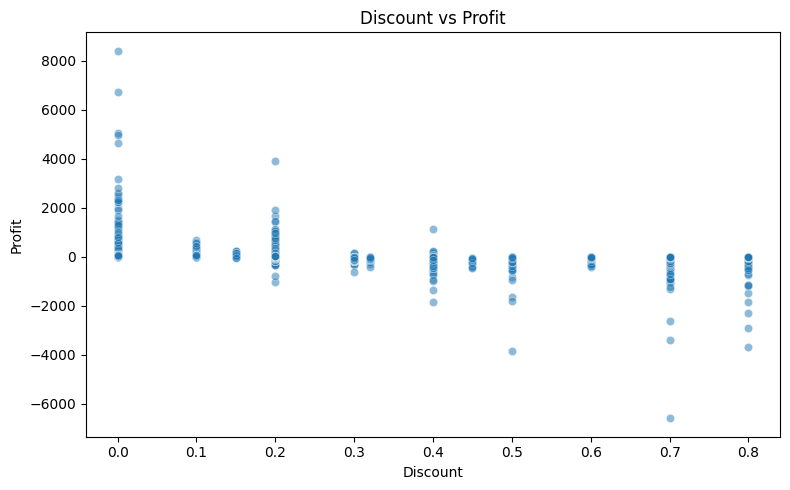

,Total_Sales,Total_Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303



FIVE BUSINESS FINDINGS
1. Highest sales month: 2018-11 - 118447.82
2. Lowest sales month: 2015-02 - 4519.89
3. Highest sales category: Technology - 836154.03
4. Most profitable category: Technology - 145454.95
5. Average profit by discount level:


,Profit
Discount,
0.00,66.90
0.10,96.06
0.15,27.29
0.20,24.70
0.30,-45.68
0.32,-88.56
0.40,-111.93
0.45,-226.65
0.50,-310.70


In [4]:

# TASK 1: SUPERSTORE SALES ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names
df.columns = df.columns.str.strip()

# Convert dates
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce')

# Handle missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()
df = df.dropna(subset=['Order Date', 'Sales', 'Profit'])

# Extract year and month
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

print("\nCleaned dataset shape:", df.shape)

# 1. Monthly Sales
monthly_sales = df.groupby('Year-Month')['Sales'].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot()
plt.title('Monthly Sales Trend')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 2. Category-wise Sales
category_sales = df.groupby('Category')['Sales'].sum().sort_values()

category_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

# 3. Category-wise Profit
category_profit = df.groupby('Category')['Profit'].sum().sort_values()

category_profit.plot(kind='bar', figsize=(8, 5))
plt.title('Profit by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.tight_layout()
plt.show()

# 4. Discount vs Profit
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5)
plt.title('Discount vs Profit')
plt.tight_layout()
plt.show()

# 5. Region-wise Performance
region_summary = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).sort_values('Total_Sales', ascending=False)

display(region_summary)

# 6. Five data-based business findings
print("\nFIVE BUSINESS FINDINGS")

print("1. Highest sales month:",
      monthly_sales.idxmax(),
      "-", round(monthly_sales.max(), 2))

print("2. Lowest sales month:",
      monthly_sales.idxmin(),
      "-", round(monthly_sales.min(), 2))

print("3. Highest sales category:",
      category_sales.idxmax(),
      "-", round(category_sales.max(), 2))

print("4. Most profitable category:",
      category_profit.idxmax(),
      "-", round(category_profit.max(), 2))

print("5. Average profit by discount level:")
display(df.groupby('Discount')['Profit'].mean().round(2))
